# Appointment Operations
## Summary
The verified extract contains **110,527 appointments**. Six invalid records are quarantined, leaving **110,521 appointments**, of which **22,314 (20.19%)** were missed.

The missed rate is **4.65%** for same-day bookings and **33.00%** for bookings at least 31 days ahead. This is an association in historical data, not evidence that changing the booking window causes attendance to improve.

**Purpose:** help an operations analyst investigate attendance patterns, check data quality, and evaluate explicit capacity assumptions. Dataset: [Medical Appointment No Shows](https://www.kaggle.com/datasets/joniarroba/noshowappointments), Joni Hoppen / Aquarela Analytics, CC BY-NC-SA 4.0.

## Context and method
One row represents one appointment, including repeat patients. The appointment field has calendar dates rather than useful visit times; both timestamp fields are normalized before lead-time subtraction. Negative age and booking-after-visit rows are quarantined. Age values above 110 are flagged and retained because age is not used here.

No-show `Yes` means **missed**. Group rates are recalculated from counts. The public application receives aggregate counts, not source record identifiers.

### Assumptions
The source outcome labels and dates are taken as supplied after validation. The extract covers April 29–June 8, 2016, not three complete months. SMS timing and assignment rules are unavailable. Intervention effects cannot be estimated from these comparisons.

### 1. Download, validate, and aggregate

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pipeline import run
plt.rcParams.update({'figure.figsize': (10, 4.6), 'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 14, 'font.size': 11, 'axes.grid': True, 'grid.alpha': .15})
artifact = run()
figures = Path('artifacts/figures')
figures.mkdir(exist_ok=True)


{
  "source_rows": 110527,
  "accepted_rows": 110521,
  "quarantined_rows": 6,
  "negative_age_rows": 1,
  "negative_lead_rows": 5,
  "age_above_110_rows": 5,
  "missing_values": 0,
  "duplicate_appointment_ids": 0,
  "unique_patients": 62299,
  "start": "2016-04-29",
  "end": "2016-06-08",
  "sha256": "4b4f258837029bd4e61ed4c9bab2ce8a3b8a299d1a4f5bdabcc98967d5e29a43",
  "missed": 22314,
  "attendance_rate": 0.7981017182254956,
  "no_show_rate": 0.2018982817745044,
  "mean_lead_days": 10.184345056595578
}


### 2. Inspect the data contract

In [2]:
display(pd.DataFrame([artifact['summary']]).T.rename(columns={0:'Value'}))
rows = pd.DataFrame(artifact['rows'])
assert rows.appointments.sum() == artifact['summary']['accepted_rows']
assert rows.missed.sum() == artifact['summary']['missed']
print('Aggregate counts reconcile to all accepted records.')

,Value
source_rows,110527
accepted_rows,110521
quarantined_rows,6
negative_age_rows,1
negative_lead_rows,5
age_above_110_rows,5
missing_values,0
duplicate_appointment_ids,0
unique_patients,62299
start,2016-04-29


Aggregate counts reconcile to all accepted records.


## Results
### Booking lead time and missed visits

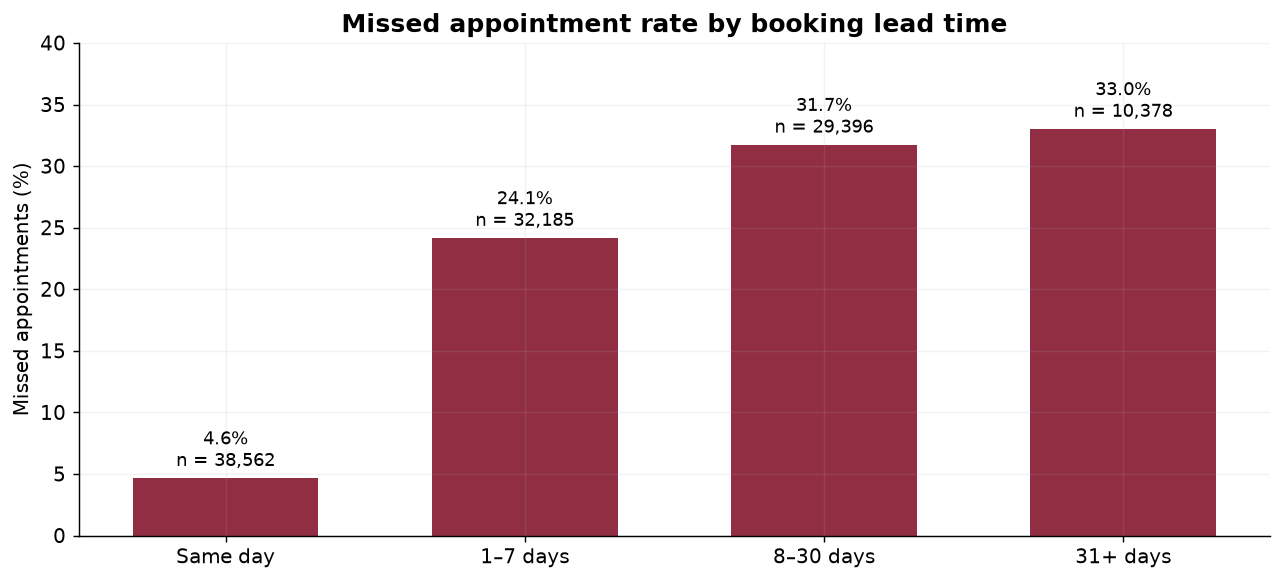

,lead_band,appointments,missed,rate
0,Same day,38562,1792,0.046471
1,1–7 days,32185,7772,0.241479
2,8–30 days,29396,9325,0.317220
3,31+ days,10378,3425,0.330025


In [3]:
lead = pd.DataFrame(artifact['lead'])
fig, ax = plt.subplots()
ax.bar(lead.lead_band, lead.rate*100, color='#922e43', width=.62)
ax.set(title='Missed appointment rate by booking lead time', ylabel='Missed appointments (%)', ylim=(0,40))
for i, r in lead.iterrows():
    ax.text(i, r.rate*100+1, f'{r.rate*100:.1f}%\nn = {r.appointments:,}', ha='center', fontsize=10)
fig.tight_layout(); fig.savefig(figures/'lead-time.png'); plt.show()
display(lead[['lead_band','appointments','missed','rate']])

Longer lead-time groups have higher missed rates in this extract. The chart includes each denominator, so small and large groups are distinguishable. Patient characteristics and appointment types could confound this association.

### Daily volume

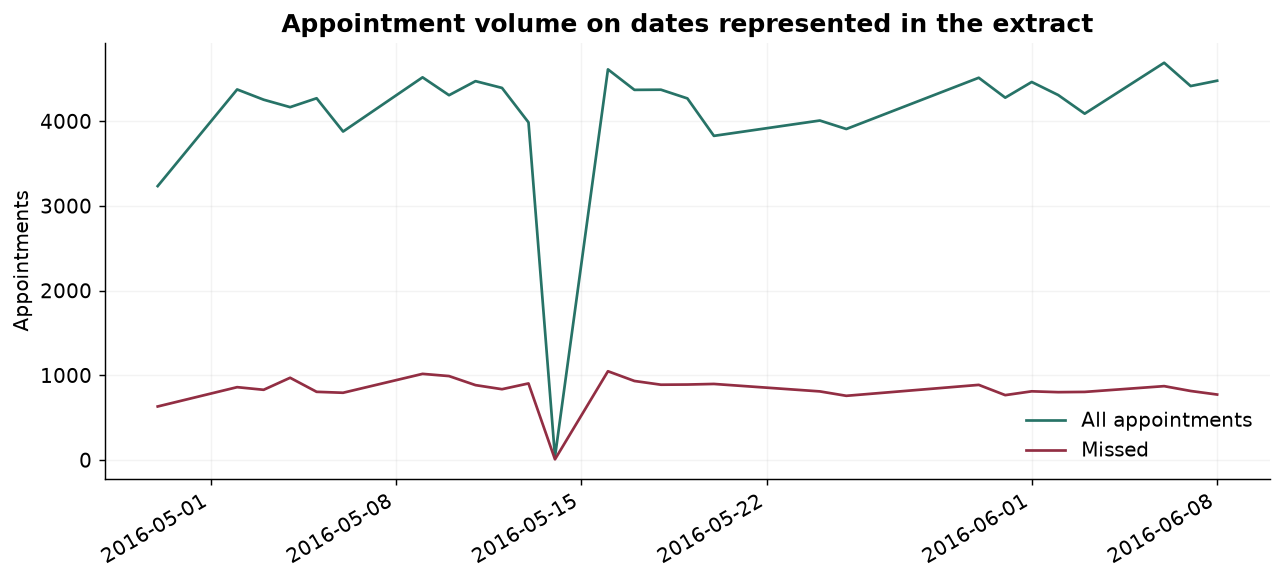

In [4]:
daily = rows.groupby('appointment_date')[['appointments','missed']].sum()
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots()
ax.plot(daily.index, daily.appointments, color='#277367', label='All appointments')
ax.plot(daily.index, daily.missed, color='#922e43', label='Missed')
ax.set(title='Appointment volume on dates represented in the extract', ylabel='Appointments')
ax.legend(frameon=False); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(figures/'daily-volume.png'); plt.show()

Dates without records are gaps in source coverage, not imputed zero-volume days. April and June are partial months; raw monthly totals should not be interpreted as a trend in demand.

### SMS comparisons within booking windows

,lead_band,message,appointments,missed,missed_rate
0,1–7 days,No recorded SMS,20637,5028,0.243640
1,1–7 days,Recorded SMS,11548,2744,0.237617
2,31+ days,No recorded SMS,3968,1489,0.375252
3,31+ days,Recorded SMS,6410,1936,0.302028
4,8–30 days,No recorded SMS,11872,4221,0.355542
5,8–30 days,Recorded SMS,17524,5104,0.291258
6,Same day,No recorded SMS,38562,1792,0.046471


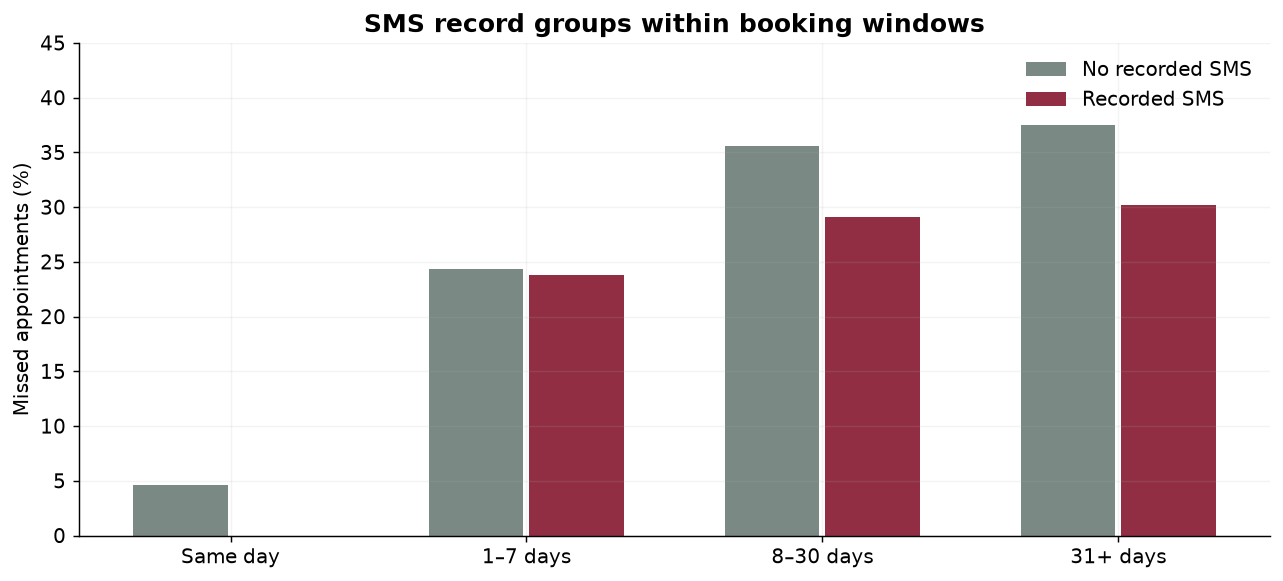

In [5]:
sms = rows.groupby(['lead_band','sms_received'])[['appointments','missed']].sum().reset_index()
sms['missed_rate'] = sms.missed / sms.appointments
sms['message'] = sms.sms_received.map({0:'No recorded SMS',1:'Recorded SMS'})
display(sms[['lead_band','message','appointments','missed','missed_rate']])
fig, ax = plt.subplots()
order = ['Same day','1–7 days','8–30 days','31+ days']
for value, color, shift in [(0,'#7b8984',-.17),(1,'#922e43',.17)]:
    group = sms[sms.sms_received==value].set_index('lead_band').reindex(order)
    ax.bar(np.arange(4)+shift, group.missed_rate*100, width=.32, color=color, label='Recorded SMS' if value else 'No recorded SMS')
ax.set(xticks=np.arange(4), xticklabels=order, ylabel='Missed appointments (%)', title='SMS record groups within booking windows', ylim=(0,45))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(figures/'sms-context.png'); plt.show()

The absence of a same-day SMS bar means no matching observations, not a 0% missed rate. The within-window comparison differs from the unadjusted headline. Neither identifies SMS effectiveness.

## Planning example

In [6]:
relative_reduction = .10
slot_minutes = 30
missed = artifact['summary']['missed']
scenario = {'Observed missed appointments':missed, 'Assumed relative reduction':relative_reduction, 'Potential recovered appointments':missed*relative_reduction, 'Potential appointment-hours':missed*relative_reduction*slot_minutes/60}
display(pd.Series(scenario))

Observed missed appointments        22314.0
Assumed relative reduction              0.1
Potential recovered appointments     2231.4
Potential appointment-hours          1115.7
dtype: float64

This is a capacity calculation under explicit assumptions, not a forecast of achieved savings. It does not establish staff availability, visit duration, costs, or the effectiveness of any intervention.

## Takeaways
Use this tool to identify questions for operations review, reproduce counts, and compare scenarios. A next study would prospectively test a specific outreach or scheduling intervention with an appropriate randomized or carefully designed comparison. The source data and derived aggregates retain CC BY-NC-SA 4.0; original project code is MIT licensed.